k1 = 3.1087, k2 = 3.8594
лямбда = 0.2870
Коэффициент сжатия альфа = 0.1077
Априорная оценка количества итераций: 3
Номер последней итерации: 2
Значение последней итерации x_n: 0.464391
Значение x_(n+1)=f(x_n) - найденный корень x*: 0.464243
Проверка g(x*): -1.34e-05


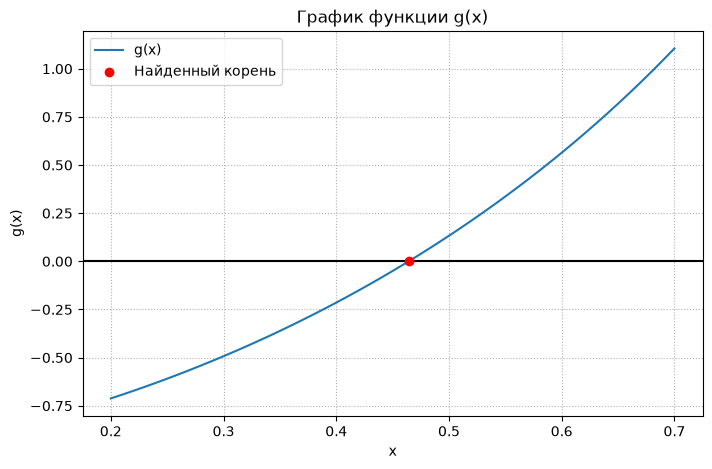

In [2]:
import math
import matplotlib.pyplot as plt

def g(x):
    return x**7 + x**3 + 2*x**2 + x - 1

def f(x, lam):
    return x - lam * g(x)

def gDerivative(x):
    return 7*x**6 + 3*x**2 + 4*x + 1

def main():
    a, b = 0.4, 0.5
    e = 1e-4
    
    k1 = gDerivative(a)
    k2 = gDerivative(b)
    lam = 2.0 / (k1 + k2)
    
    alpha = (k2 - k1) / (k2 + k1)
    
    print(f"k1 = {k1:.4f}, k2 = {k2:.4f}")
    print(f"лямбда = {lam:.4f}")
    print(f"Коэффициент сжатия альфа = {alpha:.4f}")

    x0 = (a + b) / 2.0
    x1 = f(x0, lam)
    
    nApr = math.log(e * (1 - alpha) / abs(x0 - x1)) / math.log(alpha)
    nApr = math.floor(nApr) + 1
    
    print(f"Априорная оценка количества итераций: {nApr}")

    n = 0
    xPrev = x0

    while True:
        xNext = f(xPrev, lam)
        n += 1
        error = (alpha / (1 - alpha)) * abs(xNext - xPrev)
        if error <= e:
            break
        xPrev = xNext
        
    print(f"Номер последней итерации: {n}")
    print(f"Значение последней итерации x_n: {xPrev:.6f}")
    print(f"Значение x_(n+1)=f(x_n) - найденный корень x*: {xNext:.6f}")
    print(f"Проверка g(x*): {g(xNext):.2e}")

    xVals = [a - 0.2 + i * 0.01 for i in range(int((b - a + 0.4) / 0.01) + 1)]
    yVals = [g(x) for x in xVals]
    
    plt.figure(figsize=(8, 5))
    plt.plot(xVals, yVals, label="g(x)")
    plt.axhline(0, color="black")
    plt.scatter([xNext], [g(xNext)], color="red", zorder=5, label="Найденный корень")
    
    plt.title("График функции g(x)")
    plt.xlabel("x")
    plt.ylabel("g(x)")
    plt.grid(True, linestyle=":")
    plt.legend()
    
    plt.show()

main()